# Introduction

In this notebook we will develop a model to predict the hourly generation of solar and wind power in the German bidding zone (DE-AT-LU). The models will feed on two-dimensional grid weather data from a cosmological reanalysis from the year 2023 and 2024 data. The predicted data will be the true hourly generation output of the respective technologies in the German bidding zone, available from the German Transmission system operators.

> **Note**: The datasets used in this model are quite big (~10GB in total). Running parts of this notebook will require large amounts of memory to keep the respective numpy arrays in memory. All of this code has been executed on a online cloud instance with 64GB of RAM. The minimum memory required is 32GB RAM. 8GB or 16GB is certainly not enough...

> **Note**:Weather data is originally provided in the .nc format, which can be managed using Python libraries such as netCDF4. However, installing this module and its dependencies can be cumbersome. To facilitate efficient RAM management, we preprocess all data and save it as a NumPy array in a .pkl file. We will load the grid data from the .pkl file and then use this data to train and test the model.

## Contents

* [Step 1](#step0): Load Generation Dataset (Feature Engineering)
* [Step 2](#step0): Visualize grid weather data
* [Step 2](#step1): Preprocess data
* [Step 3](#step2): Train a neural network for solar power generation
* [Step 4](#step3): Train a neural network for wind power generation
---

In [41]:
# !pip install netCDF4
# !pip install cartopy

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import xarray as xr
import warnings as wn
wn.filterwarnings('ignore')

# Feature Engineering


1. **Load the Dataset**:  
   The dataset is loaded from a CSV file into a Pandas DataFrame using `pd.read_csv()`. The file contains energy generation data categorized by type (e.g., solar, wind_onshore, wind_offshore) and includes a time column labeled `MTU`.

2. **Select Relevant Columns**:  
   Only the columns `MTU`, `solar`, `wind_onshore`, and `wind_offshore` are retained in the DataFrame to focus on these variables for analysis. 

3. **Inspect Data**:  
   `df.info()` is called to display information about the DataFrame, including column data types and the presence of null values.

4. **Filter Rows by Date**:  
   - The `MTU` column is converted to a `datetime` format to enable date filtering. 
   - Rows with dates falling in the years 2023 and 2024 are extracted using the `dt.year` attribute.
   - The filtered DataFrame is reset to have sequential indexing using `df.reset_index(drop=True)`.

5. **Check for Missing Values**:  
   - The count of missing values in each column is calculated using `df.isnull().sum()`.
   - A new DataFrame (`null_counts_df`) is created to organize the column names and their respective null value counts for visualization.


In [53]:
df = pd.read_csv('/kaggle/input/generation-dataset/20200101-20241030-gen_per_prod_type.csv')
df.tail(5)

,MTU,biomass,brown_coal,hard_coal,wind_offshore,pumped_hydro,solar,river_hydro,wind_onshore,nuclear,other
169435,2024-10-30 22:45:00,4443.0,11944.0,6528.0,1619.0,133.0,0.0,1488.0,4412.0,NaN,182.0
169436,2024-10-30 23:00:00,4435.0,11817.0,6289.0,1632.0,123.0,0.0,1489.0,4444.0,NaN,182.0
169437,2024-10-30 23:15:00,4429.0,11579.0,6099.0,1847.0,75.0,0.0,1488.0,4454.0,NaN,179.0
169438,2024-10-30 23:30:00,4432.0,11248.0,5926.0,2049.0,62.0,0.0,1490.0,4463.0,NaN,175.0
169439,2024-10-30 23:45:00,4412.0,10733.0,5561.0,2041.0,87.0,0.0,1491.0,4524.0,NaN,175.0


In [54]:
df = df[['MTU','solar','wind_onshore','wind_offshore']]
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 169440 entries, 0 to 169439
Data columns (total 4 columns):
 #   Column         Non-Null Count   Dtype  
---  ------         --------------   -----  
 0   MTU            169440 non-null  object 
 1   solar          169428 non-null  float64
 2   wind_onshore   169428 non-null  float64
 3   wind_offshore  169440 non-null  float64
dtypes: float64(3), object(1)
memory usage: 5.2+ MB


In [55]:
# Filter rows for the years 2023 and 2024

df['MTU'] = pd.to_datetime(df['MTU'])

# Ensure the MTU column is in datetime format
df['MTU'] = pd.to_datetime(df['MTU'])

# Filter rows for the years 2023 and 2024
df = df[(df['MTU'].dt.year == 2023) | (df['MTU'].dt.year == 2024)]

# Display the filtered DataFrame
df = df.reset_index(drop=True)
df

,MTU,solar,wind_onshore,wind_offshore
0,2023-01-01 00:00:00,2.0,28627.0,2737.0
1,2023-01-01 00:15:00,1.0,28676.0,2974.0
2,2023-01-01 00:30:00,1.0,29249.0,3268.0
3,2023-01-01 00:45:00,1.0,28457.0,3258.0
4,2023-01-01 01:00:00,1.0,29329.0,3142.0
...,...,...,...,...
64219,2024-10-30 22:45:00,0.0,4412.0,1619.0
64220,2024-10-30 23:00:00,0.0,4444.0,1632.0
64221,2024-10-30 23:15:00,0.0,4454.0,1847.0
64222,2024-10-30 23:30:00,0.0,4463.0,2049.0


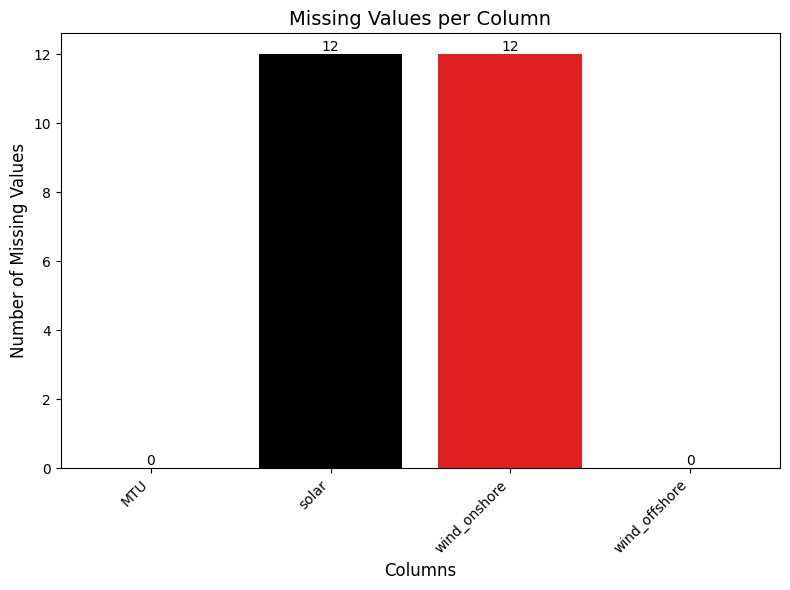

In [56]:
import seaborn as sns
import matplotlib.pyplot as plt

# Calculate null value counts
null_counts = df.isnull().sum()

# Create a DataFrame for visualization
null_counts_df = null_counts.reset_index()
null_counts_df.columns = ['Column', 'Null Count']

# Plot the null value counts using Seaborn
plt.figure(figsize=(8, 6))
sns.barplot(data=null_counts_df, x='Column', y='Null Count', palette=['Red','Black'])

# Add annotations
for i, row in null_counts_df.iterrows():
    plt.text(i, row['Null Count'], f"{row['Null Count']}", ha='center', va='bottom', fontsize=10)

# Customize the plot
plt.title('Missing Values per Column', fontsize=14)
plt.xlabel('Columns', fontsize=12)
plt.ylabel('Number of Missing Values', fontsize=12)
plt.xticks(rotation=45, ha='right')  # Rotate x-axis labels for better readability
plt.tight_layout()

# Show the plot
plt.show()

# Fill Missing values

**Explaination**

The below code uses `IterativeImputer` to handle missing values in the numerical columns of a DataFrame by modeling each column as a function of the others. First, it identifies numerical columns using `select_dtypes`. Then, the `IterativeImputer` is configured to perform up to 10 iterations (`max_iter=10`) and ensure reproducibility (`random_state=42`). The imputation process initializes missing values and iteratively refines estimates using regression models based on the other columns. Finally, the imputed values are assigned back to the original DataFrame, effectively filling in missing values with contextually informed estimates.

In [2]:
import pandas as pd
import numpy as np
from sklearn.experimental import enable_iterative_imputer  # noqa
from sklearn.impute import IterativeImputer


# Apply Iterative Imputer only on numerical columns
numerical_cols = df.select_dtypes(include=[np.number]).columns
imputer = IterativeImputer(max_iter=10, random_state=42)

# Impute missing values
df[numerical_cols] = imputer.fit_transform(df[numerical_cols])

In [58]:
df.isnull().any()

MTU              False
solar            False
wind_onshore     False
wind_offshore    False
dtype: bool

In [21]:
# Save clean data into csv
df.to_csv('dataset_2023_24.csv', index=False)

## Download Dimensions data

**Explaination**

This code uses the xarray Python library to download .nc files from the url-link of dataset, enabling access to the timestep data within the files. Additionally, the netCDF4 library is used to extract dimensions related to power generation in Germany. This processed data can then be visualized on graphs and utilized for further analysis.

In [3]:
import os
import re
import requests
from urllib.parse import urljoin

# Define the base URL where the files are hosted
base_url = "https://opendata.dwd.de/climate_environment/CDC/grids_germany/hourly/hostrada/wind_direction/"

# Directory to save downloaded files
output_dir = "Wind_direction_data"
os.makedirs(output_dir, exist_ok=True)

# Function to download a file
def download_file(url, save_path):
    try:
        response = requests.get(url, stream=True)
        if response.status_code == 200:
            with open(save_path, "wb") as f:
                for chunk in response.iter_content(chunk_size=8192):
                    f.write(chunk)
            print(f"Downloaded: {save_path}")
        else:
            print(f"Failed to download: {url} (Status Code: {response.status_code})")
    except Exception as e:
        print(f"Error downloading {url}: {e}")

# Function to get the list of files from the server
def get_file_list(url):
    try:
        response = requests.get(url)
        if response.status_code == 200:
            # Parse the HTML or directory listing for file names
            return re.findall(r'href="([^"]*\.nc)"', response.text)
        else:
            print(f"Failed to retrieve file list from: {url} (Status Code: {response.status_code})")
            return []
    except Exception as e:
        print(f"Error fetching file list from {url}: {e}")
        return []

# Get the list of .nc files from the server
file_list = get_file_list(base_url)

# Filter for 2023 and 2024 files based on the naming pattern
pattern = r"sfcWind_direction_1hr_HOSTRADA-v1-0_BE_gn_(2023)\d+"  # Match the specific format for 2023 and 2024
filtered_files = [f for f in file_list if re.search(pattern, f)]

# Download each filtered file
for file_name in filtered_files:
    file_url = urljoin(base_url, file_name)
    save_path = os.path.join(output_dir, file_name)
    download_file(file_url, save_path)

Downloaded: Wind_direction_data/sfcWind_direction_1hr_HOSTRADA-v1-0_BE_gn_2023010100-2023013123.nc
Downloaded: Wind_direction_data/sfcWind_direction_1hr_HOSTRADA-v1-0_BE_gn_2023020100-2023022823.nc
Downloaded: Wind_direction_data/sfcWind_direction_1hr_HOSTRADA-v1-0_BE_gn_2023030100-2023033123.nc
Downloaded: Wind_direction_data/sfcWind_direction_1hr_HOSTRADA-v1-0_BE_gn_2023040100-2023043023.nc
Downloaded: Wind_direction_data/sfcWind_direction_1hr_HOSTRADA-v1-0_BE_gn_2023050100-2023053123.nc
Downloaded: Wind_direction_data/sfcWind_direction_1hr_HOSTRADA-v1-0_BE_gn_2023060100-2023063023.nc
Downloaded: Wind_direction_data/sfcWind_direction_1hr_HOSTRADA-v1-0_BE_gn_2023070100-2023073123.nc
Downloaded: Wind_direction_data/sfcWind_direction_1hr_HOSTRADA-v1-0_BE_gn_2023080100-2023083123.nc
Downloaded: Wind_direction_data/sfcWind_direction_1hr_HOSTRADA-v1-0_BE_gn_2023090100-2023093023.nc
Downloaded: Wind_direction_data/sfcWind_direction_1hr_HOSTRADA-v1-0_BE_gn_2023100100-2023103123.nc
Downloaded

In [61]:
import xarray as xr
import os

# Directory containing .nc files
directory = "/kaggle/working/Wind_Speed_data/"

# Get a list of all .nc files in the directory
nc_files = [os.path.join(directory, f) for f in os.listdir(directory) if f.endswith(".nc")]

# Open and combine all .nc files
rads = xr.open_mfdataset(nc_files, chunks={'time': 100}, combine='by_coords')

In [66]:
rads = xr.open_mfdataset("/kaggle/working/Radiation_data/rsds_1hr_HOSTRADA-v1-0_BE_gn_2023010100-2023013123.nc", chunks={'time': 100}, combine='by_coords')
wind_speed = xr.open_mfdataset("/kaggle/working/Wind_Speed_data/sfcWind_1hr_HOSTRADA-v1-0_BE_gn_2023010100-2023013123.nc", chunks={'time': 100}, combine='by_coords')
wind_direction = xr.open_mfdataset("/kaggle/working/Wind_direction_data/sfcWind_direction_1hr_HOSTRADA-v1-0_BE_gn_2023010100-2023013123.nc", chunks={'time': 100}, combine='by_coords')

In [67]:
rads_time = np.array(rads.time)
wind_speed_time = np.array(wind_speed.time)
wind_dir_time = np.array(wind_direction.time)
wind_dir_time[0:10]

array(['2023-01-01T00:00:00.000000000', '2023-01-01T01:00:00.000000000',
       '2023-01-01T02:00:00.000000000', '2023-01-01T03:00:00.000000000',
       '2023-01-01T04:00:00.000000000', '2023-01-01T05:00:00.000000000',
       '2023-01-01T06:00:00.000000000', '2023-01-01T07:00:00.000000000',
       '2023-01-01T08:00:00.000000000', '2023-01-01T09:00:00.000000000'],
      dtype='datetime64[ns]')

In [69]:
from netCDF4 import Dataset
import numpy as np
import pandas as pd

# Reading in the NetCDF file
rad_data = Dataset(r'/kaggle/working/Radiation_data/rsds_1hr_HOSTRADA-v1-0_BE_gn_2023010100-2023013123.nc', 'r')
wind_speed_data = Dataset(r'/kaggle/working/Wind_Speed_data/sfcWind_1hr_HOSTRADA-v1-0_BE_gn_2023010100-2023013123.nc', 'r')
wind_direction_data = Dataset(r'/kaggle/working/Wind_direction_data/sfcWind_direction_1hr_HOSTRADA-v1-0_BE_gn_2023010100-2023013123.nc', 'r')

In [71]:
print(rad_data.variables.keys())
print(wind_speed_data.variables.keys())
print(wind_direction_data.variables.keys())

dict_keys(['X', 'Y', 'lon', 'lat', 'time', 'rsds', 'crs', 'time_bnds'])
dict_keys(['X', 'Y', 'lon', 'lat', 'time', 'sfcWind', 'crs'])
dict_keys(['X', 'Y', 'lon', 'lat', 'time', 'sfcWind_direction', 'crs'])


# Plot Dimensions data into Graphs

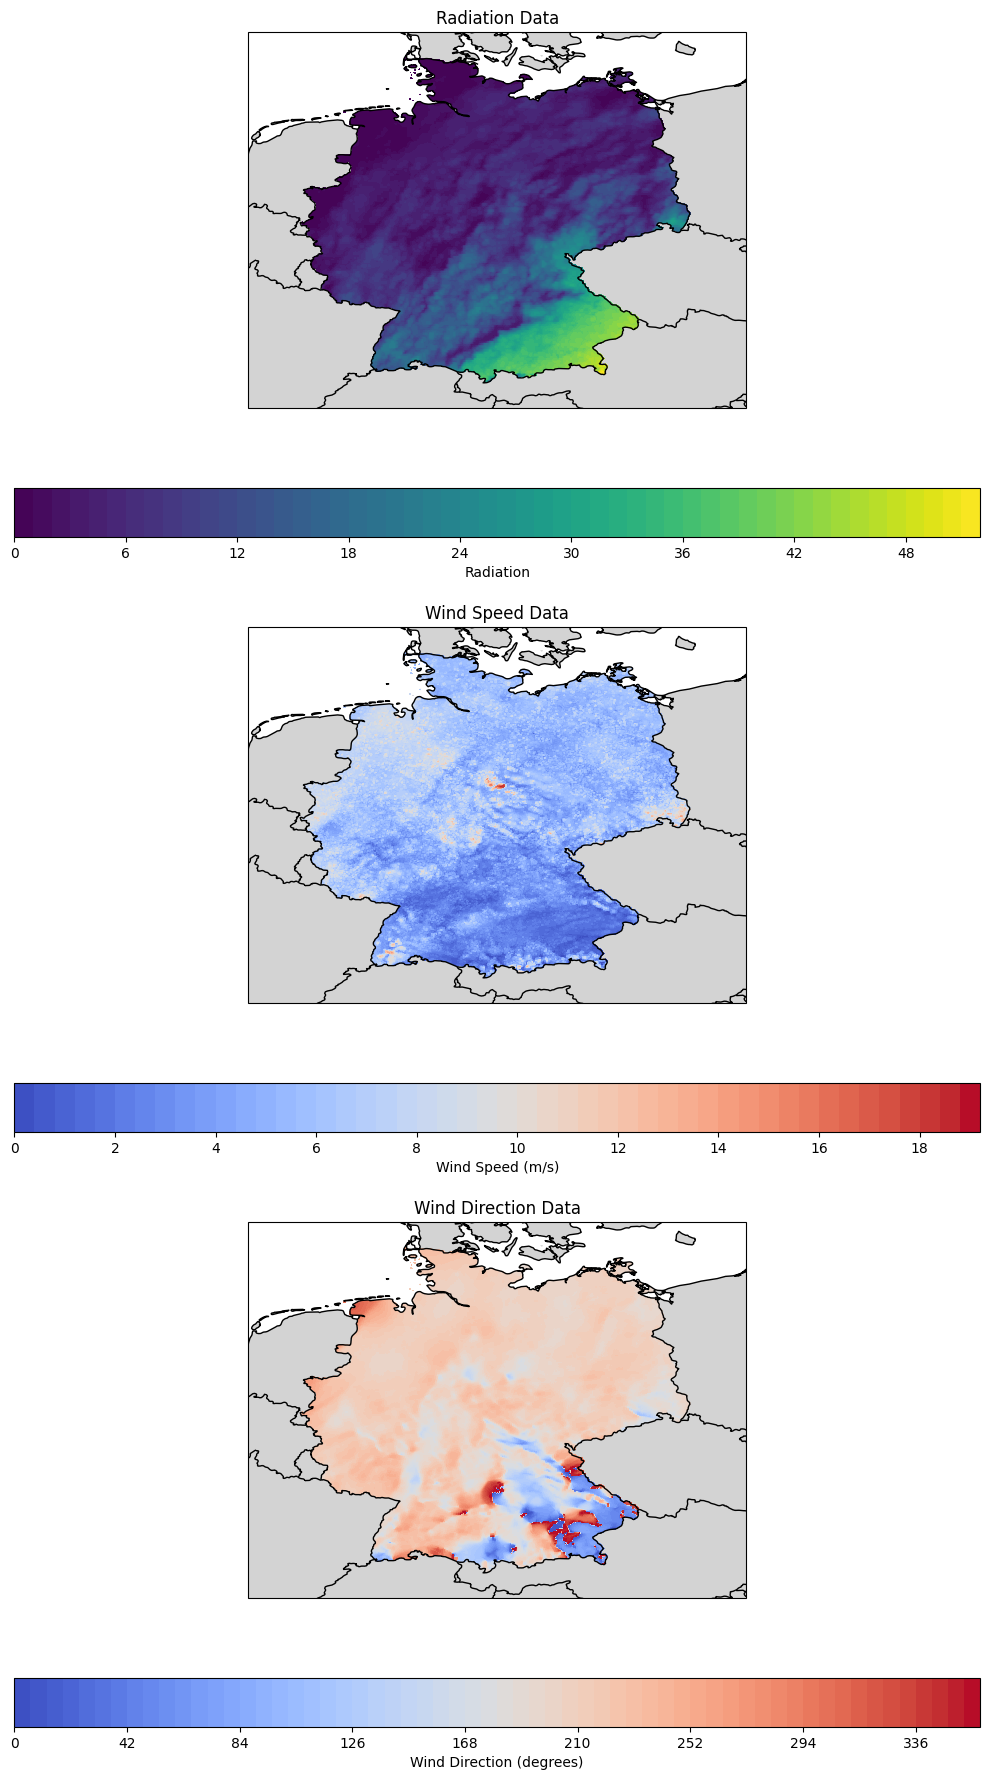

In [75]:
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature

# Example data for radiation, wind speed, and wind direction
# Replace these with your actual data variables
radiation = rad_data.variables['rsds'][32, :, :]  # Radiation data
wind_speed = wind_speed_data.variables['sfcWind'][32, :, :]  # Wind speed data
wind_direction = wind_direction_data.variables['sfcWind_direction'][32, :, :]  # Wind direction data

# Latitude and longitude for each variable
radiation_lat = rad_data.variables['lat'][:]
radiation_lon = rad_data.variables['lon'][:]

wind_speed_lat = wind_speed_data.variables['lat'][:]
wind_speed_lon = wind_speed_data.variables['lon'][:]

wind_direction_lat = wind_direction_data.variables['lat'][:]
wind_direction_lon = wind_direction_data.variables['lon'][:]

# Create the figure and subplots
fig, axs = plt.subplots(3, 1, figsize=(10, 18), subplot_kw={'projection': ccrs.PlateCarree()})

# Radiation subplot
c1 = axs[0].contourf(radiation_lon, radiation_lat, radiation, 60, cmap='viridis', transform=ccrs.PlateCarree())
axs[0].coastlines()
axs[0].add_feature(cfeature.BORDERS)
axs[0].add_feature(cfeature.LAND, facecolor='lightgray')
fig.colorbar(c1, ax=axs[0], orientation='horizontal', label='Radiation')
axs[0].set_title('Radiation Data')

# Wind speed subplot
c2 = axs[1].contourf(wind_speed_lon, wind_speed_lat, wind_speed, 60, cmap='coolwarm', transform=ccrs.PlateCarree())
axs[1].coastlines()
axs[1].add_feature(cfeature.BORDERS)
axs[1].add_feature(cfeature.LAND, facecolor='lightgray')
fig.colorbar(c2, ax=axs[1], orientation='horizontal', label='Wind Speed (m/s)')
axs[1].set_title('Wind Speed Data')

# Wind direction subplot
c3 = axs[2].contourf(wind_direction_lon, wind_direction_lat, wind_direction, 60, cmap='coolwarm', transform=ccrs.PlateCarree())
axs[2].coastlines()
axs[2].add_feature(cfeature.BORDERS)
axs[2].add_feature(cfeature.LAND, facecolor='lightgray')
fig.colorbar(c3, ax=axs[2], orientation='horizontal', label='Wind Direction (degrees)')
axs[2].set_title('Wind Direction Data')

# Adjust layout
plt.tight_layout()

# Show the plot
plt.show()


In [2]:
import xarray as xr
import os

# Directory containing .nc files
directory = "/kaggle/working/Wind_Speed_data"

# Get a list of all .nc files in the directory
nc_files = [os.path.join(directory, f) for f in os.listdir(directory) if f.endswith(".nc")]
nc_files

['/kaggle/working/Wind_Speed_data/sfcWind_1hr_HOSTRADA-v1-0_BE_gn_2024060100-2024063023.nc',
 '/kaggle/working/Wind_Speed_data/sfcWind_1hr_HOSTRADA-v1-0_BE_gn_2024070100-2024073123.nc',
 '/kaggle/working/Wind_Speed_data/sfcWind_1hr_HOSTRADA-v1-0_BE_gn_2024050100-2024053123.nc',
 '/kaggle/working/Wind_Speed_data/sfcWind_1hr_HOSTRADA-v1-0_BE_gn_2024080100-2024083123.nc',
 '/kaggle/working/Wind_Speed_data/sfcWind_1hr_HOSTRADA-v1-0_BE_gn_2024030100-2024033123.nc',
 '/kaggle/working/Wind_Speed_data/sfcWind_1hr_HOSTRADA-v1-0_BE_gn_2024110100-2024113023.nc',
 '/kaggle/working/Wind_Speed_data/sfcWind_1hr_HOSTRADA-v1-0_BE_gn_2024020100-2024022923.nc',
 '/kaggle/working/Wind_Speed_data/sfcWind_1hr_HOSTRADA-v1-0_BE_gn_2024100100-2024103123.nc',
 '/kaggle/working/Wind_Speed_data/sfcWind_1hr_HOSTRADA-v1-0_BE_gn_2024040100-2024043023.nc',
 '/kaggle/working/Wind_Speed_data/sfcWind_1hr_HOSTRADA-v1-0_BE_gn_2024090100-2024093023.nc',
 '/kaggle/working/Wind_Speed_data/sfcWind_1hr_HOSTRADA-v1-0_BE_gn_2024

In [3]:
# Filter files for 2023 only
wind_speed_2023_files = [path for path in nc_files if '_2023' in path]
wind_speed_2023_files.sort()
wind_speed_2023_files

[]

In [4]:
# Filter files for 2024 only
wind_speed_2024_files = [path for path in nc_files if '_2024' in path]
wind_speed_2024_files.sort()
wind_speed_2024_files

['/kaggle/working/Wind_Speed_data/sfcWind_1hr_HOSTRADA-v1-0_BE_gn_2024010100-2024013123.nc',
 '/kaggle/working/Wind_Speed_data/sfcWind_1hr_HOSTRADA-v1-0_BE_gn_2024020100-2024022923.nc',
 '/kaggle/working/Wind_Speed_data/sfcWind_1hr_HOSTRADA-v1-0_BE_gn_2024030100-2024033123.nc',
 '/kaggle/working/Wind_Speed_data/sfcWind_1hr_HOSTRADA-v1-0_BE_gn_2024040100-2024043023.nc',
 '/kaggle/working/Wind_Speed_data/sfcWind_1hr_HOSTRADA-v1-0_BE_gn_2024050100-2024053123.nc',
 '/kaggle/working/Wind_Speed_data/sfcWind_1hr_HOSTRADA-v1-0_BE_gn_2024060100-2024063023.nc',
 '/kaggle/working/Wind_Speed_data/sfcWind_1hr_HOSTRADA-v1-0_BE_gn_2024070100-2024073123.nc',
 '/kaggle/working/Wind_Speed_data/sfcWind_1hr_HOSTRADA-v1-0_BE_gn_2024080100-2024083123.nc',
 '/kaggle/working/Wind_Speed_data/sfcWind_1hr_HOSTRADA-v1-0_BE_gn_2024090100-2024093023.nc',
 '/kaggle/working/Wind_Speed_data/sfcWind_1hr_HOSTRADA-v1-0_BE_gn_2024100100-2024103123.nc',
 '/kaggle/working/Wind_Speed_data/sfcWind_1hr_HOSTRADA-v1-0_BE_gn_2024

# Data Preprocessing

**Explanation**

The purpose of this code is to preprocess a NetCDF dataset containing power generation data by extracting specific variables and dimensions, downsampling the data, and saving the processed data into a pickle file for further use. Here’s a step-by-step breakdown:

1. **Open Dataset and Extract Time Information**:  
   The dataset (specified by `dataset_path`) is opened using the xarray library. Time data is extracted into a NumPy array (`data_time`), which represents the temporal dimension of the dataset.

2. **Read NetCDF File and Extract Variable Dimensions**:  
   The NetCDF4 library is used to open the dataset in 'read' mode to extract detailed information about the specified variable (`variable_name`). The code checks if the variable exists in the dataset and raises an error if not. Then, it extracts the dimensions (time, latitude, and longitude) of the variable.

3. **Preallocate Array for Data**:  
   An empty NumPy array (`data_array`) is created with the same dimensions as the data (time, latitude, longitude) to store the extracted variable data.

4. **Fill the Data Array**:  
   The data from the specified variable is loaded into the `data_array`. This step loops through all timesteps and assigns the corresponding data to the preallocated array.

5. **Downsample the Data**:  
   The data is downsampled by the factor specified in `downsample_factor`. This reduces the spatial resolution by selecting every nth latitude and longitude value.

6. **Create Dictionary with Processed Data**:  
   A dictionary (`data_dict`) is created to store both the time data (`MTU`) and the processed power generation data (from `gen_name`). This structure helps organize the data before saving it.

7. **Save Data to Pickle File**:  
   The dictionary is serialized and saved to a pickle file, allowing for efficient storage and future retrieval of the processed data.


In [9]:
import numpy as np
import xarray as xr
import pickle
from netCDF4 import Dataset

def preprocess_data(dataset_path, variable_name, gen_name, downsample_factor=2):
    
    # Open the dataset
    try:
        dataset = xr.open_dataset(dataset_path)
    except Exception as e:
        raise RuntimeError(f"Failed to open dataset: {e}")

    # Extract time information
    data_time = np.array(dataset['time'])

    # Read the NetCDF file for detailed variable extraction
    try:
        netcdf_data = Dataset(dataset_path, 'r')
    except Exception as e:
        raise RuntimeError(f"Failed to read NetCDF data: {e}")

    if variable_name not in netcdf_data.variables:
        raise KeyError(f"Variable '{variable_name}' not found in dataset.")

    # Extract dimensions
    time_dim = netcdf_data.variables[variable_name].shape[0]
    lat_dim = netcdf_data.variables[variable_name].shape[1]
    lon_dim = netcdf_data.variables[variable_name].shape[2]

    # Preallocate array for data
    data_array = np.empty((time_dim, lat_dim, lon_dim), dtype=np.float32)

    # Fill the array with data
    for i in range(time_dim):
        data_array[i, :, :] = netcdf_data.variables[variable_name][i, :, :]

    # Downsample the data
    data_array = data_array[:, ::downsample_factor, ::downsample_factor]

    # Create a dictionary with the processed data
    data_dict = {
        'MTU': data_time,
        gen_name: data_array
    }

    # Generate the pickle file name
    start_time_str = str(data_time[0])[:10].replace("-", "")
    pickle_file_name = f"{gen_name}_{start_time_str}.pkl"

    # Save dictionary to a pickle file
    try:
        with open(pickle_file_name, 'wb') as pickle_file:
            pickle.dump(data_dict, pickle_file)
    except Exception as e:
        raise RuntimeError(f"Failed to save pickle file: {e}")

    return pickle_file_name


In [10]:
variable_name='sfcWind'
gen_name='Wind_Power'

for dataset_path in wind_speed_2024_files:
    # Preprocess the data
    file_name = preprocess_data(dataset_path, variable_name, gen_name)

    print(f"Data saved to {file_name}")

Data saved to Wind_Power_20240101.pkl
Data saved to Wind_Power_20240201.pkl
Data saved to Wind_Power_20240301.pkl
Data saved to Wind_Power_20240401.pkl
Data saved to Wind_Power_20240501.pkl
Data saved to Wind_Power_20240601.pkl
Data saved to Wind_Power_20240701.pkl
Data saved to Wind_Power_20240801.pkl
Data saved to Wind_Power_20240901.pkl
Data saved to Wind_Power_20241001.pkl
Data saved to Wind_Power_20241101.pkl


In [52]:
import pickle

# Path to the .pkl file
file_path = "/kaggle/working/Wind_Power_20241101.pkl"

# Reading the .pkl file
with open(file_path, "rb") as file:
    data2 = pickle.load(file)

In [53]:
data2 = data2['Wind_Power']

In [54]:
data.shape,data2.shape

((7320, 469, 360), (720, 469, 360))

In [55]:
data= np.concatenate((data, data2),axis=0)
data.shape

(8040, 469, 360)

In [56]:
with open('wind_power_data_2024.pkl', 'wb') as pickle_file:
    pickle.dump(data, pickle_file)

# Solar Radiation Power Generation Prediction

In [6]:
# Load Solar Radiation Dimensions Dataset
import pickle

# Path to the .pkl file
file_path = "/kaggle/input/solar-radiation-data/radiation_data_2023.pkl"

# Reading the .pkl file
with open(file_path, "rb") as file:
    data = pickle.load(file)

In [7]:
data.shape

(8760, 469, 360)

In [8]:
# Load Time steps data
file_path = "/kaggle/input/radiation-time/rads_time.npy"
time_data = np.load(file_path)
time_data[0:10]

array(['2023-01-01T00:00:00.000000000', '2023-01-01T01:00:00.000000000',
       '2023-01-01T02:00:00.000000000', '2023-01-01T03:00:00.000000000',
       '2023-01-01T04:00:00.000000000', '2023-01-01T05:00:00.000000000',
       '2023-01-01T06:00:00.000000000', '2023-01-01T07:00:00.000000000',
       '2023-01-01T08:00:00.000000000', '2023-01-01T09:00:00.000000000'],
      dtype='datetime64[ns]')

In [9]:
# Filter out the timesteps of year of 2023
time_data = time_data[0:8760]
time_df = pd.DataFrame({
    'MTU':time_data
})
time_df.head()

,MTU
0,2023-01-01 00:00:00
1,2023-01-01 01:00:00
2,2023-01-01 02:00:00
3,2023-01-01 03:00:00
4,2023-01-01 04:00:00


In [10]:
# Filter rows where "MTU" in DataFrame is present in the "MTU" column of the dictionary
radiation_gen_data = df[df['MTU'].isin(time_df['MTU'])]
radiation_gen_data

,MTU,solar,wind_offshore,wind_onshore
0,2023-01-01 00:00:00,2.0,2737.0,28627.0
4,2023-01-01 01:00:00,1.0,3142.0,29329.0
8,2023-01-01 02:00:00,2.0,4039.0,28961.0
12,2023-01-01 03:00:00,1.0,3628.0,27747.0
16,2023-01-01 04:00:00,2.0,3286.0,26997.0
...,...,...,...,...
35020,2023-12-31 19:00:00,3.0,6300.0,29037.0
35024,2023-12-31 20:00:00,3.0,6291.0,30338.0
35028,2023-12-31 21:00:00,3.0,6341.0,29885.0
35032,2023-12-31 22:00:00,3.0,6359.0,29510.0


In [11]:
radiation_gen_data = radiation_gen_data['solar']
radiation_gen_data

0        2.0
4        1.0
8        2.0
12       1.0
16       2.0
        ... 
35020    3.0
35024    3.0
35028    3.0
35032    3.0
35036    3.0
Name: solar, Length: 8760, dtype: float64

# Split Dataset into Training and Testing

1. This code preprocesses power generation data for use in a Convolutional Neural Network (CNN) by applying Min-Max scaling and reshaping the data. First, it flattens the data to scale it between 0 and 1 using `MinMaxScaler` to ensure each feature is within the same range.
2. Then, the data is reshaped back to its original dimensions and further transformed into a 2D format suitable for CNN input. The data is split into training and validation sets using `train_test_split`, with 10% of the data reserved for validation.
3.  The input data is expanded to add a single channel dimension, making it compatible for grayscale CNN processing. 

In [12]:
from sklearn.preprocessing import MinMaxScaler
import numpy as np


# Flatten the data to apply Min-Max Scaling
scaler = MinMaxScaler()
data_flat = data.reshape(data.shape[0], -1)  # Flatten the last two dimensions (744, 938*720)

# Apply Min-Max scaling
data_scaled_flat = scaler.fit_transform(data_flat)  # Each feature is scaled between [0, 1]

# Reshape back to the original shape
data_scaled_flat = data_scaled_flat.reshape(data.shape)

# Reshape data for 2D CNN (flatten the second and third dimensions into one)
radiation_data_2d = data_scaled_flat.reshape(data.shape[0], data.shape[1], -1)  # Shape: (744, 938, 720)

# Split data into training and validation sets
from sklearn.model_selection import train_test_split
X_train, X_val, Y_train, Y_val = train_test_split(
    radiation_data_2d, radiation_gen_data , test_size=0.1, random_state=42
)

# Expand dimensions for CNN input (grayscale or single channel)
X_train = np.expand_dims(X_train, axis=-1)  # Shape: (train_samples, 938, 720, 1)
X_val = np.expand_dims(X_val, axis=-1)      # Shape: (val_samples, 938, 720, 1)

print("Scaled Data Shape for CNN:")
print("X_train:", X_train.shape)
print("X_val:", X_val.shape)


Scaled Data Shape for CNN:
X_train: (7884, 469, 360, 1)
X_val: (876, 469, 360, 1)


# Train Neural Network on Radiation Power Dimension Dataset

**Explaination**

I used the 2023 dataset for training and the 2024 dataset for testing predictions. I initialized a Convolutional Neural Network (CNN) architecture with a linear output activation function for the final layer. After training the model on the 2023 data, I saved the trained model in `.h5` format. Next, I loaded the 2024 dataset for both wind and solar power generation, along with actual power generation data from a CSV file. The model achieved approximately 97% accuracy (R² score) for solar power and about 95% for wind power generation, which is quite accurate. Finally, I loaded the trained model and tested it on the 2024 data, as shown in the graphs.

In [13]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout
from sklearn.model_selection import train_test_split
import numpy as np

In [14]:
# Define a 2D CNN model
model = Sequential([
    Conv2D(32, (3, 3), activation='relu', input_shape=(X_train.shape[1], X_train.shape[2], 1)),
    MaxPooling2D((2, 2)),
    Conv2D(64, (3, 3), activation='relu'),
    MaxPooling2D((2, 2)),
    Flatten(),
    Dense(128, activation='relu'),
    Dropout(0.5),
    Dense(1, activation='linear')  # Assuming solar_radiation is a regression target
])

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                      │ (None, 467, 358, 32)        │             320 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d (MaxPooling2D)         │ (None, 233, 179, 32)        │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_1 (Conv2D)                    │ (None, 231, 177, 64)        │          18,496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_1 (MaxPooling2D)       │ (None, 115, 88, 64)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten (Flatten)                    │ (None, 647680)              │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 128)                 │      82,903,168 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 1)                   │             129 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 82,922,113 (316.32 MB)

 Trainable params: 82,922,113 (316.32 MB)

 Non-trainable params: 0 (0.00 B)

In [15]:
from tensorflow.keras.callbacks import EarlyStopping

# Define the EarlyStopping callback
early_stopping = EarlyStopping(
    monitor='val_loss',  # Metric to monitor
    patience=3,          # Number of epochs to wait before stopping if no improvement
    restore_best_weights=True  # Restore model weights from the epoch with the best value of monitored metric
)

# Compile the model
model.compile(optimizer='adam', loss='mean_squared_error', metrics=['mae'])

# Train the model with early stopping
history = model.fit(
    X_train, Y_train,
    validation_data=(X_val, Y_val),
    epochs=15,           # Set a high number of epochs; early stopping will handle when to stop
    batch_size=32,
    callbacks=[early_stopping]  # Include the callback in training
)

# Evaluate the model
loss, mae = model.evaluate(X_val, Y_val)
print(f"Validation Loss: {loss}, MAE: {mae}")


Epoch 1/15
247/247 ━━━━━━━━━━━━━━━━━━━━ 35s 107ms/step - loss: 36091972.0000 - mae: 2880.9773 - val_loss: 2898735.7500 - val_mae: 943.5266
Epoch 2/15
247/247 ━━━━━━━━━━━━━━━━━━━━ 17s 70ms/step - loss: 5603862.0000 - mae: 1180.6407 - val_loss: 3064109.0000 - val_mae: 930.4915
Epoch 3/15
247/247 ━━━━━━━━━━━━━━━━━━━━ 17s 70ms/step - loss: 5300910.5000 - mae: 1191.3163 - val_loss: 3021694.2500 - val_mae: 919.5882
Epoch 4/15
247/247 ━━━━━━━━━━━━━━━━━━━━ 18s 72ms/step - loss: 5532289.0000 - mae: 1218.2461 - val_loss: 2417191.0000 - val_mae: 828.6948
Epoch 5/15
247/247 ━━━━━━━━━━━━━━━━━━━━ 17s 69ms/step - loss: 4950734.0000 - mae: 1127.5542 - val_loss: 4604820.0000 - val_mae: 1151.7671
Epoch 6/15
247/247 ━━━━━━━━━━━━━━━━━━━━ 17s 69ms/step - loss: 5553509.5000 - mae: 1237.3811 - val_loss: 2696725.2500 - val_mae: 871.5651
Epoch 7/15
247/247 ━━━━━━━━━━━━━━━━━━━━ 18s 71ms/step - loss: 5057676.5000 - mae: 1148.3112 - val_loss: 2331210.7500 - val_mae: 812.5642
Epoch 8/15
247/247 ━━━━━━━━━━━━━━━━━━━

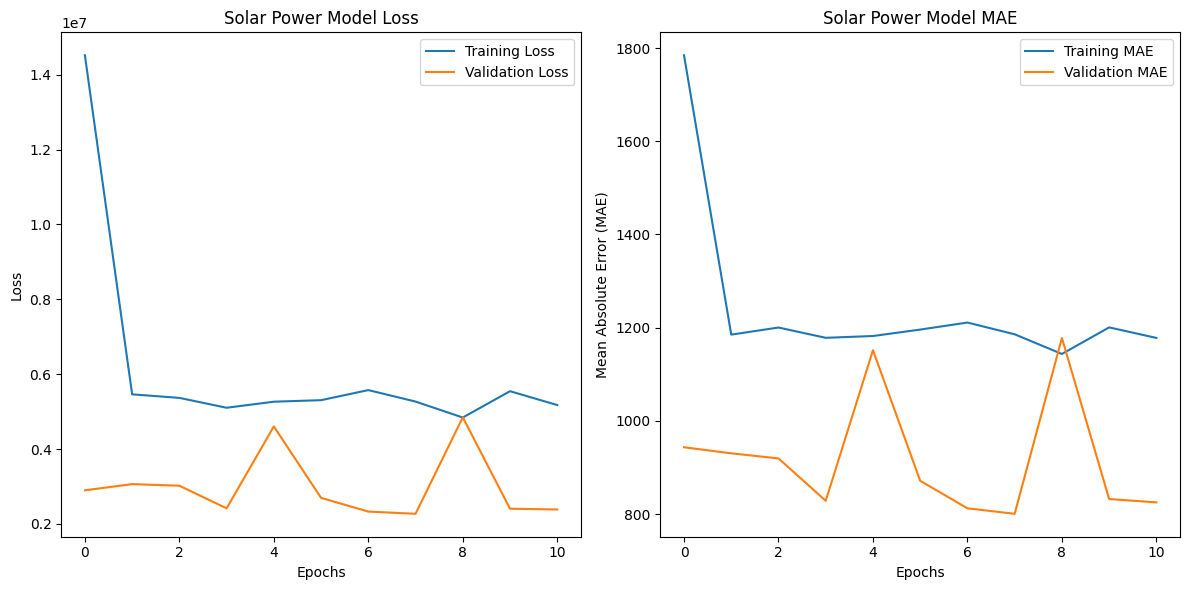

In [16]:
import matplotlib.pyplot as plt

# Plot the training history
def plot_history(history):
    # Plot training & validation loss
    plt.figure(figsize=(12, 6))

    # Loss plot
    plt.subplot(1, 2, 1)
    plt.plot(history.history['loss'], label='Training Loss')
    plt.plot(history.history['val_loss'], label='Validation Loss')
    plt.title('Solar Power Model Loss')
    plt.xlabel('Epochs')
    plt.ylabel('Loss')
    plt.legend()

    # MAE plot
    plt.subplot(1, 2, 2)
    plt.plot(history.history['mae'], label='Training MAE')
    plt.plot(history.history['val_mae'], label='Validation MAE')
    plt.title('Solar Power Model MAE')
    plt.xlabel('Epochs')
    plt.ylabel('Mean Absolute Error (MAE)')
    plt.legend()

    plt.tight_layout()
    plt.show()

# Call the function with the model history
plot_history(history)


28/28 ━━━━━━━━━━━━━━━━━━━━ 1s 23ms/step
R^2 Score: 0.9767


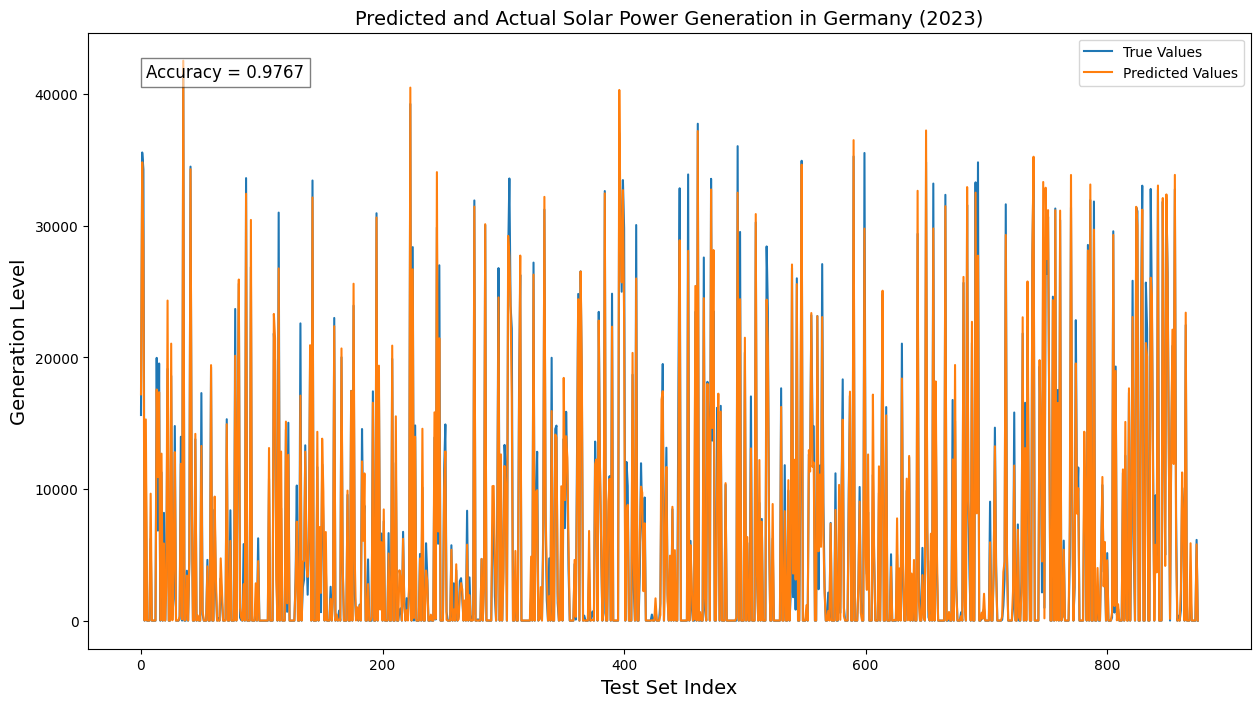

In [17]:
from sklearn.metrics import r2_score
import matplotlib.pyplot as plt
import pandas as pd

# Assume Y_test contains the true values and Y_pred contains the model's predictions
# Replace Y_test and Y_pred with the actual test and predicted data
Y_test = np.array(Y_val)  # Replace this with the actual test set true values
Y_pred = model.predict(X_val).flatten()  # Get predictions and flatten to match the shape of Y_test

# Calculate R^2 value
r2 = r2_score(Y_test, Y_pred)
print(f"R^2 Score: {r2:.4f}")

# Create a DataFrame for visualization
df = pd.DataFrame({
    'True Values': Y_test,
    'Predicted Values': Y_pred
})

# Plot results
fig, ax = plt.subplots(figsize=(15, 8))
df.plot(ax=ax)
ax.set_title('Predicted and Actual Solar Power Generation in Germany (2023)', fontsize=14)
ax.set_ylabel('Generation Level', fontsize=14)
ax.set_xlabel('Test Set Index', fontsize=14)
plt.text(0.05, 0.95, f'Accuracy = {r2:.4f}', transform=ax.transAxes, fontsize=12, 
         verticalalignment='top', bbox=dict(facecolor='white', alpha=0.5))
plt.show()


28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step
R^2 Score: 0.9767


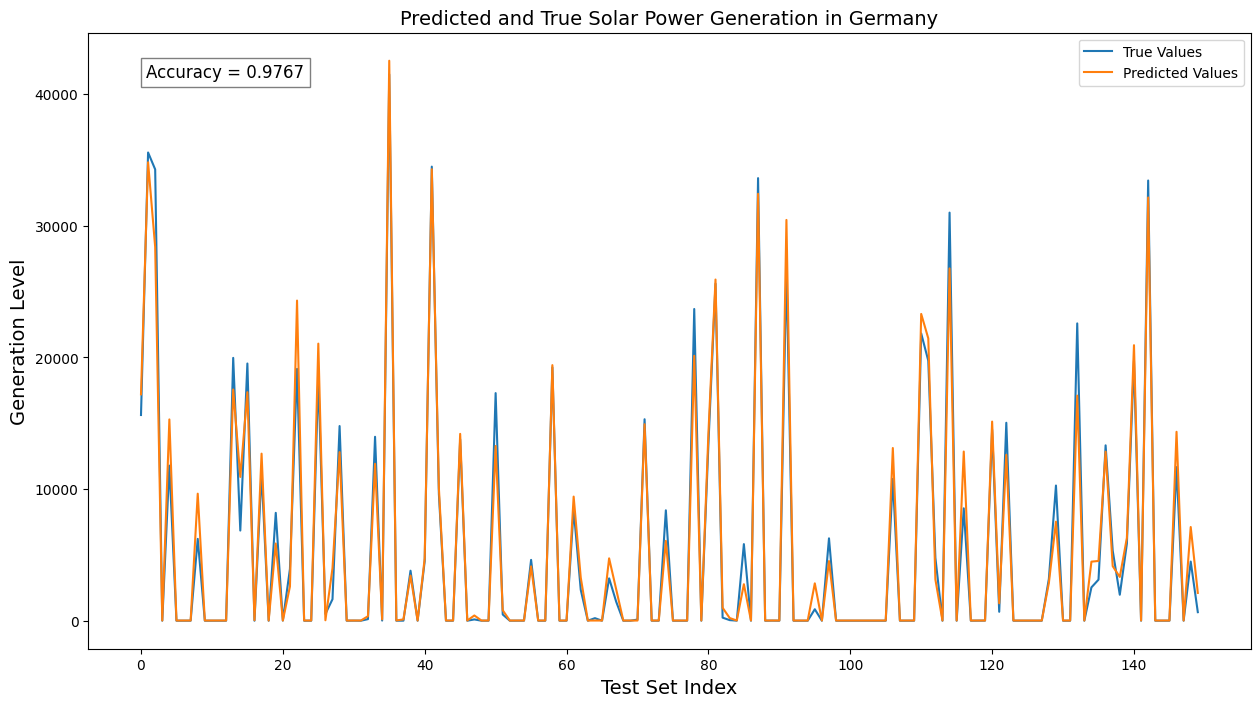

In [18]:
from sklearn.metrics import r2_score
import matplotlib.pyplot as plt
import pandas as pd

# Assume Y_test contains the true values and Y_pred contains the model's predictions
# Replace Y_test and Y_pred with the actual test and predicted data
Y_test = np.array(Y_val)  # Replace this with the actual test set true values
Y_pred = model.predict(X_val).flatten()  # Get predictions and flatten to match the shape of Y_test

# Calculate R^2 value
r2 = r2_score(Y_test, Y_pred)
print(f"R^2 Score: {r2:.4f}")

# Create a DataFrame for visualization
df = pd.DataFrame({
    'True Values': Y_test[0:150],
    'Predicted Values': Y_pred[0:150]
})

# Plot results
fig, ax = plt.subplots(figsize=(15, 8))
df.plot(ax=ax)
ax.set_title('Predicted and True Solar Power Generation in Germany', fontsize=14)
ax.set_ylabel('Generation Level', fontsize=14)
ax.set_xlabel('Test Set Index', fontsize=14)
plt.text(0.05, 0.95, f'Accuracy = {r2:.4f}', transform=ax.transAxes, fontsize=12, 
         verticalalignment='top', bbox=dict(facecolor='white', alpha=0.5))
plt.show()


# Save Trained model of Solar Power

In [4]:
model.save("model_solar_Power.h5")

# Load Trained Model

In [104]:
import tensorflow as tf

# Load the model from a .h5 file
model = tf.keras.models.load_model('/kaggle/input/solar-power-model/model_solar_Power.h5')

# Display the model summary (optional)
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                      │ (None, 467, 358, 32)        │             320 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d (MaxPooling2D)         │ (None, 233, 179, 32)        │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_1 (Conv2D)                    │ (None, 231, 177, 64)        │          18,496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_1 (MaxPooling2D)       │ (None, 115, 88, 64)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten (Flatten)                    │ (None, 647680)              │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 128)                 │      82,903,168 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 1)                   │             129 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 82,922,115 (316.32 MB)

 Trainable params: 82,922,113 (316.32 MB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 2 (12.00 B)

In [117]:
timesteps = np.load('/kaggle/input/radiation-time/rads_time.npy')
timesteps[8760:].shape

(7320,)

In [126]:
time_data = timesteps[8760:]
time_df = pd.DataFrame({
    'MTU':time_data
})
time_df.head()

,MTU
0,2024-01-01 00:00:00
1,2024-01-01 01:00:00
2,2024-01-01 02:00:00
3,2024-01-01 03:00:00
4,2024-01-01 04:00:00


In [129]:
time_df.shape

(7320, 1)

In [130]:
df.isnull().sum()

MTU              0
solar            0
wind_offshore    0
wind_onshore     0
dtype: int64

In [146]:
# Filter rows where "MTU" in DataFrame is present in the "MTU" column of the dictionary
radiation_gen_data = df[df['MTU'].isin(time_df['MTU'])]
radiation_gen_data.tail(10)

,MTU,solar,wind_offshore,wind_onshore
64184,2024-10-30 14:00:00,8613.0,1836.0,5463.0
64188,2024-10-30 15:00:00,5392.0,2140.0,5137.0
64192,2024-10-30 16:00:00,1703.0,2077.0,4796.0
64196,2024-10-30 17:00:00,10.0,1887.0,4869.0
64200,2024-10-30 18:00:00,0.0,1743.0,4817.0
64204,2024-10-30 19:00:00,0.0,1641.0,4637.0
64208,2024-10-30 20:00:00,0.0,1541.0,4732.0
64212,2024-10-30 21:00:00,0.0,1397.0,4546.0
64216,2024-10-30 22:00:00,0.0,1636.0,4261.0
64220,2024-10-30 23:00:00,0.0,1632.0,4444.0


In [119]:
data = data[0:7320]
data.shape

(7320, 469, 360)

In [120]:
from sklearn.preprocessing import MinMaxScaler
import numpy as np


# Flatten the data to apply Min-Max Scaling
scaler = MinMaxScaler()
data_flat = data.reshape(data.shape[0], -1)  # Flatten the last two dimensions (744, 938*720)

# Apply Min-Max scaling
data_scaled_flat = scaler.fit_transform(data_flat)  # Each feature is scaled between [0, 1]

# Reshape back to the original shape
data_scaled_flat = data_scaled_flat.reshape(data.shape)

# Reshape data for 2D CNN (flatten the second and third dimensions into one)
radiation_data = data_scaled_flat.reshape(data.shape[0], data.shape[1], -1)  # Shape: (744, 938, 720)


# Expand dimensions for CNN input (grayscale or single channel)
radiation_data = np.expand_dims(radiation_data, axis=-1)  # Shape: (train_samples, 938, 720, 1)

print("Ready 2024 Data for CNN model prediction:")
print("Radiation Data:", radiation_data.shape)

Ready 2024 Data for CNN model prediction:
Radiation Data: (7320, 469, 360, 1)


In [154]:
Prediction_2024 = model.predict(radiation_data).flatten()  # Get predictions of 2024 data

229/229 ━━━━━━━━━━━━━━━━━━━━ 4s 15ms/step


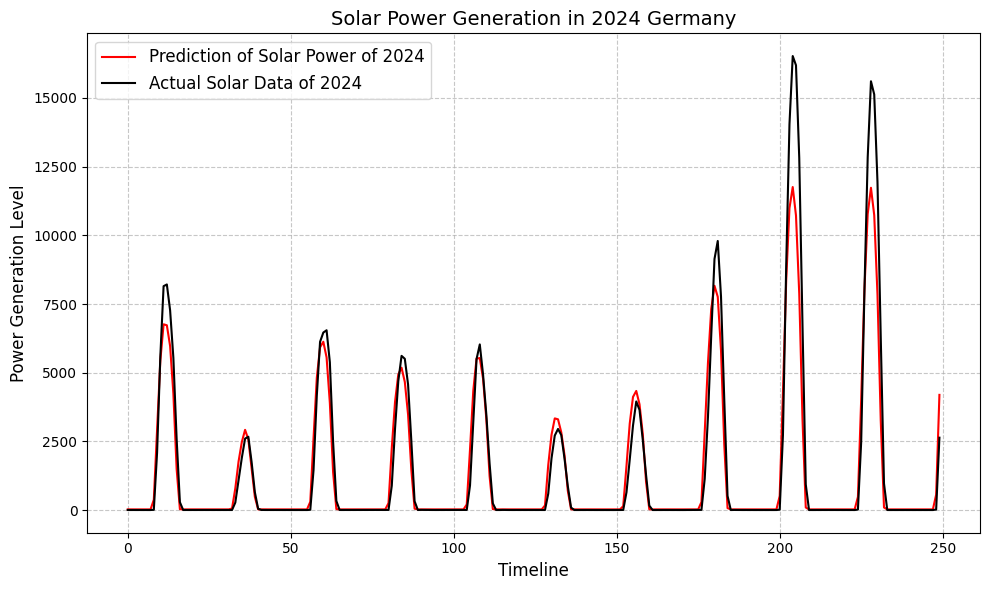

In [157]:
import matplotlib.pyplot as plt
import numpy as np

# Sample data (replace with your actual arrays)
prediction = Prediction_2024[0:250]
solar_data = np.array(radiation_gen_data['solar'])[0:250]

# Plot the line graph
plt.figure(figsize=(10, 6))  # Set the figure size

# Plot both data sets
plt.plot(prediction, label='Prediction of Solar Power of 2024', color='red')
plt.plot(solar_data, label='Actual Solar Data of 2024', color='black')

# Add title and labels
plt.title('Solar Power Generation in 2024 Germany', fontsize=14)
plt.ylabel('Power Generation Level', fontsize=12)
plt.xlabel('Timeline', fontsize=12)

# Add legend
plt.legend(fontsize=12)

# Grid for better readability
plt.grid(True, linestyle='--', alpha=0.7)

# Show the plot
plt.tight_layout()
plt.show()


In [166]:
# Define the start and end times
start_time = pd.Timestamp('2024-01-01 00:00:00')
end_time = pd.Timestamp('2024-10-30 23:00:00')

# Generate a range of timestamps with a 1-hour interval
timestamps = pd.date_range(start=start_time, end=end_time, freq='H')

Prediction_2024 = Prediction_2024[0:7295]

In [167]:
Prediction_2024.shape

(7295,)

In [168]:
timestamps

DatetimeIndex(['2024-01-01 01:00:00', '2024-01-01 02:00:00',
               '2024-01-01 03:00:00', '2024-01-01 04:00:00',
               '2024-01-01 05:00:00', '2024-01-01 06:00:00',
               '2024-01-01 07:00:00', '2024-01-01 08:00:00',
               '2024-01-01 09:00:00', '2024-01-01 10:00:00',
               ...
               '2024-10-30 14:00:00', '2024-10-30 15:00:00',
               '2024-10-30 16:00:00', '2024-10-30 17:00:00',
               '2024-10-30 18:00:00', '2024-10-30 19:00:00',
               '2024-10-30 20:00:00', '2024-10-30 21:00:00',
               '2024-10-30 22:00:00', '2024-10-30 23:00:00'],
              dtype='datetime64[ns]', length=7295, freq='h')

In [171]:
solar_power = pd.DataFrame({
    'MTU':timestamps,
    'Solar':Prediction_2024

})

solar_power.sample(10)

,MTU,Solar
3566,2024-05-28 15:00:00,26132.908203
4361,2024-06-30 18:00:00,6945.353027
3752,2024-06-05 09:00:00,20302.177734
3846,2024-06-09 07:00:00,10695.563477
689,2024-01-29 18:00:00,24.398264
1208,2024-02-20 09:00:00,3531.744629
6914,2024-10-15 03:00:00,24.398264
2635,2024-04-19 20:00:00,24.412786
5524,2024-08-18 05:00:00,24.398264
5239,2024-08-06 08:00:00,16308.004883


### Save Predicted Data into CSV file

In [173]:
solar_power.reset_index(
    drop=True
).to_csv('solar.csv', index=False)

# Wind Data Generation and Prediction

In [28]:
import pickle

# Path to the .pkl file
file_path = "/kaggle/input/wind-speed-data/wind_speed_data.pkl"

# Reading the .pkl file 
with open(file_path, "rb") as file:
    data = pickle.load(file)

In [29]:
data.shape

(7296, 469, 360)

In [30]:
# Load Time steps data
file_path = "/kaggle/input/radiation-time/rads_time.npy"
time_data = np.load(file_path)

In [34]:
time_data = time_data[0:7296]
time_df = pd.DataFrame({
    'MTU':time_data
})
time_df.head()

,MTU
0,2023-01-01 00:00:00
1,2023-01-01 01:00:00
2,2023-01-01 02:00:00
3,2023-01-01 03:00:00
4,2023-01-01 04:00:00


In [35]:
time_df.tail()

,MTU
7291,2023-10-31 19:00:00
7292,2023-10-31 20:00:00
7293,2023-10-31 21:00:00
7294,2023-10-31 22:00:00
7295,2023-10-31 23:00:00


In [36]:
# Filter rows where "MTU" in DataFrame is present in the "MTU" column of the dictionary
wind_power_gen_data = df[df['MTU'].isin(time_df['MTU'])]
wind_power_gen_data

,MTU,solar,wind_offshore,wind_onshore
0,2023-01-01 00:00:00,2.0,2737.0,28627.0
4,2023-01-01 01:00:00,1.0,3142.0,29329.0
8,2023-01-01 02:00:00,2.0,4039.0,28961.0
12,2023-01-01 03:00:00,1.0,3628.0,27747.0
16,2023-01-01 04:00:00,2.0,3286.0,26997.0
...,...,...,...,...
29164,2023-10-31 19:00:00,5.0,1374.0,16712.0
29168,2023-10-31 20:00:00,2.0,1320.0,16012.0
29172,2023-10-31 21:00:00,2.0,1372.0,15123.0
29176,2023-10-31 22:00:00,5.0,1526.0,13864.0


In [37]:
wind_power_gen_data['Wind_Power_gen'] = wind_power_gen_data['wind_offshore'] + wind_power_gen_data['wind_onshore']

In [38]:
wind_power_gen_data = wind_power_gen_data['Wind_Power_gen']

In [39]:
wind_power_gen_data.shape

(7296,)

# Split data into Train and testing

In [40]:
from sklearn.preprocessing import MinMaxScaler
import numpy as np


# Flatten the data to apply Min-Max Scaling
scaler = MinMaxScaler()
data_flat = data.reshape(data.shape[0], -1)  # Flatten the last two dimensions (744, 938*720)

# Apply Min-Max scaling
data_scaled_flat = scaler.fit_transform(data_flat)  # Each feature is scaled between [0, 1]

# Reshape back to the original shape
data_scaled_flat = data_scaled_flat.reshape(data.shape)

# Reshape data for 2D CNN (flatten the second and third dimensions into one)
wind_data_2d = data_scaled_flat.reshape(data.shape[0], data.shape[1], -1)  # Shape: (744, 938, 720)

# Split data into training and validation sets
from sklearn.model_selection import train_test_split
X_train, X_val, Y_train, Y_val = train_test_split(
    wind_data_2d, wind_power_gen_data , test_size=0.1, random_state=42
)

# Expand dimensions for CNN input (grayscale or single channel)
X_train = np.expand_dims(X_train, axis=-1)  # Shape: (train_samples, 938, 720, 1)
X_val = np.expand_dims(X_val, axis=-1)      # Shape: (val_samples, 938, 720, 1)

print("Scaled Data Shape for CNN:")
print("X_train:", X_train.shape)
print("X_val:", X_val.shape)


Scaled Data Shape for CNN:
X_train: (6566, 469, 360, 1)
X_val: (730, 469, 360, 1)


In [41]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout
from sklearn.model_selection import train_test_split
import numpy as np

In [42]:
# Define a 2D CNN model
model = Sequential([
    Conv2D(32, (3, 3), activation='relu', input_shape=(X_train.shape[1], X_train.shape[2], 1)),
    MaxPooling2D((2, 2)),
    Conv2D(64, (3, 3), activation='relu'),
    MaxPooling2D((2, 2)),
    Flatten(),
    Dense(128, activation='relu'),
    Dropout(0.5),
    Dense(1, activation='linear')  # Assuming solar_radiation is a regression target
])

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                      │ (None, 467, 358, 32)        │             320 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d (MaxPooling2D)         │ (None, 233, 179, 32)        │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_1 (Conv2D)                    │ (None, 231, 177, 64)        │          18,496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_1 (MaxPooling2D)       │ (None, 115, 88, 64)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten (Flatten)                    │ (None, 647680)              │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 128)                 │      82,903,168 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 1)                   │             129 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 82,922,113 (316.32 MB)

 Trainable params: 82,922,113 (316.32 MB)

 Non-trainable params: 0 (0.00 B)

In [43]:
from tensorflow.keras.callbacks import EarlyStopping

# Define the EarlyStopping callback
early_stopping = EarlyStopping(
    monitor='val_loss',  # Metric to monitor
    patience=5,          # Number of epochs to wait before stopping if no improvement
    restore_best_weights=True  # Restore model weights from the epoch with the best value of monitored metric
)

# Compile the model
model.compile(optimizer='adam', loss='mean_squared_error', metrics=['mae'])

# Train the model with early stopping
history = model.fit(
    X_train, Y_train,
    validation_data=(X_val, Y_val),
    epochs=50,           # Set a high number of epochs; early stopping will handle when to stop
    batch_size=32,
    callbacks=[early_stopping]  # Include the callback in training
)

# Evaluate the model
loss, mae = model.evaluate(X_val, Y_val)
print(f"Validation Loss: {loss}, MAE: {mae}")


Epoch 1/50
206/206 ━━━━━━━━━━━━━━━━━━━━ 33s 117ms/step - loss: 121884984.0000 - mae: 8150.1528 - val_loss: 31892552.0000 - val_mae: 4592.0830
Epoch 2/50
206/206 ━━━━━━━━━━━━━━━━━━━━ 15s 72ms/step - loss: 35704616.0000 - mae: 4727.7656 - val_loss: 21254674.0000 - val_mae: 3717.3787
Epoch 3/50
206/206 ━━━━━━━━━━━━━━━━━━━━ 15s 72ms/step - loss: 25093572.0000 - mae: 3908.0916 - val_loss: 14671708.0000 - val_mae: 2981.5720
Epoch 4/50
206/206 ━━━━━━━━━━━━━━━━━━━━ 15s 70ms/step - loss: 18394546.0000 - mae: 3241.5820 - val_loss: 15551495.0000 - val_mae: 3027.2805
Epoch 5/50
206/206 ━━━━━━━━━━━━━━━━━━━━ 15s 70ms/step - loss: 18192696.0000 - mae: 3195.7466 - val_loss: 16899164.0000 - val_mae: 3219.3540
Epoch 6/50
206/206 ━━━━━━━━━━━━━━━━━━━━ 15s 72ms/step - loss: 17714958.0000 - mae: 3162.4702 - val_loss: 11284623.0000 - val_mae: 2584.2593
Epoch 7/50
206/206 ━━━━━━━━━━━━━━━━━━━━ 15s 72ms/step - loss: 17440478.0000 - mae: 3112.7402 - val_loss: 10405107.0000 - val_mae: 2459.3376
Epoch 8/50
206/206

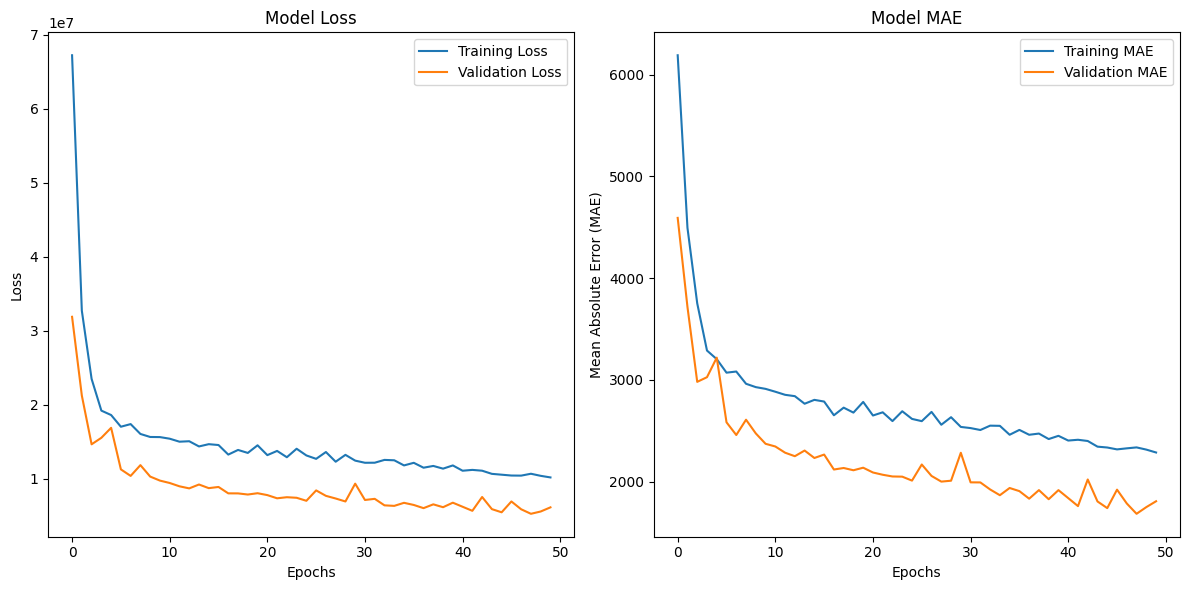

In [44]:
import matplotlib.pyplot as plt

# Plot the training history
def plot_history(history):
    # Plot training & validation loss
    plt.figure(figsize=(12, 6))

    # Loss plot
    plt.subplot(1, 2, 1)
    plt.plot(history.history['loss'], label='Training Loss')
    plt.plot(history.history['val_loss'], label='Validation Loss')
    plt.title('Model Loss')
    plt.xlabel('Epochs')
    plt.ylabel('Loss')
    plt.legend()

    # MAE plot
    plt.subplot(1, 2, 2)
    plt.plot(history.history['mae'], label='Training MAE')
    plt.plot(history.history['val_mae'], label='Validation MAE')
    plt.title('Model MAE')
    plt.xlabel('Epochs')
    plt.ylabel('Mean Absolute Error (MAE)')
    plt.legend()

    plt.tight_layout()
    plt.show()

# Call the function with the model history
plot_history(history)


23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step
R^2 Score: 0.9559


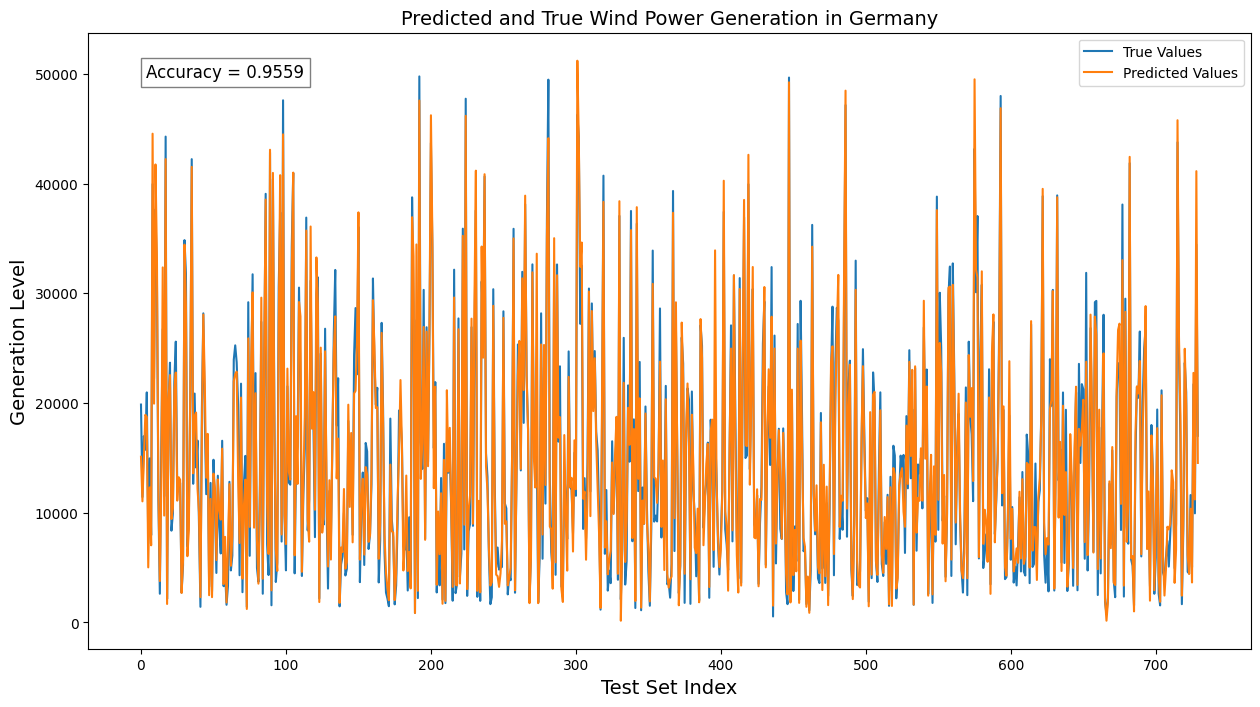

In [46]:
from sklearn.metrics import r2_score
import matplotlib.pyplot as plt
import pandas as pd

# Assume Y_test contains the true values and Y_pred contains the model's predictions
# Replace Y_test and Y_pred with the actual test and predicted data
Y_test = np.array(Y_val)  # Replace this with the actual test set true values
Y_pred = model.predict(X_val).flatten()  # Get predictions and flatten to match the shape of Y_test

# Calculate R^2 value
r2 = r2_score(Y_test, Y_pred)
print(f"R^2 Score: {r2:.4f}")

# Create a DataFrame for visualization
df = pd.DataFrame({
    'True Values': Y_test,
    'Predicted Values': Y_pred
})

# Plot results
fig, ax = plt.subplots(figsize=(15, 8))
df.plot(ax=ax)
ax.set_title('Predicted and True Wind Power Generation in Germany', fontsize=14)
ax.set_ylabel('Generation Level', fontsize=14)
ax.set_xlabel('Test Set Index', fontsize=14)
plt.text(0.05, 0.95, f'Accuracy = {r2:.4f}', transform=ax.transAxes, fontsize=12, 
         verticalalignment='top', bbox=dict(facecolor='white', alpha=0.5))
plt.show()


23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step
R^2 Score: 0.9559


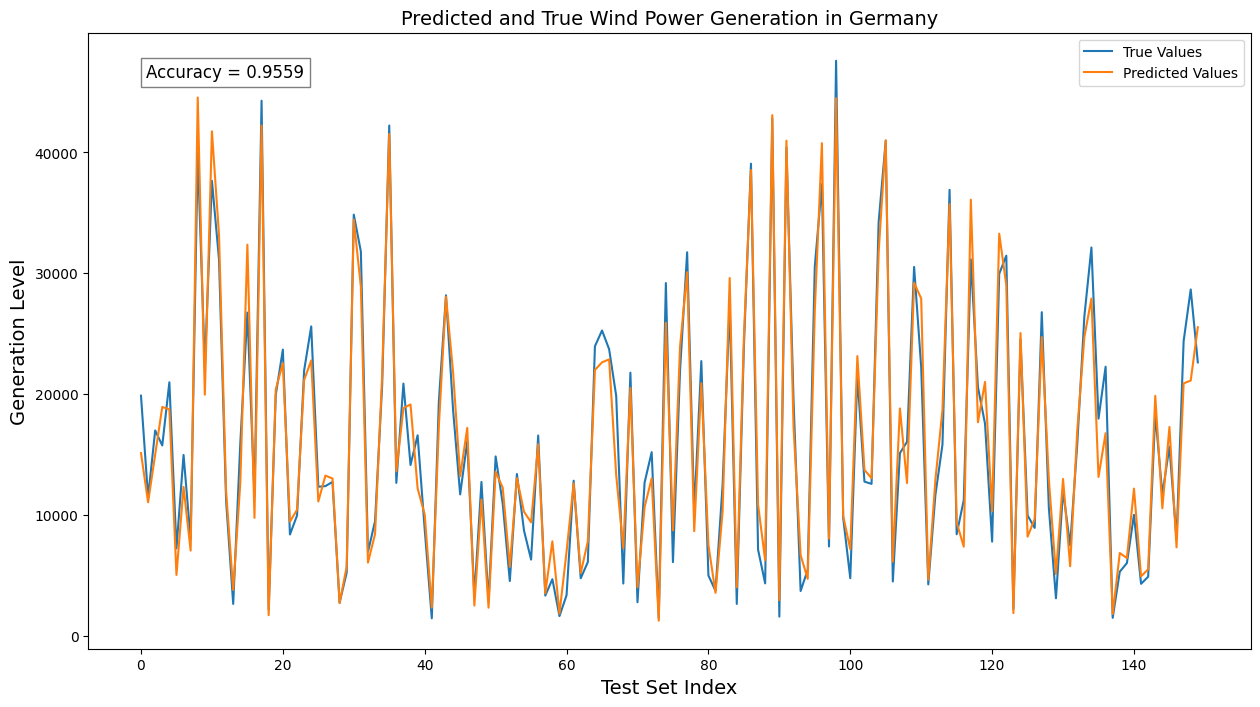

In [48]:
from sklearn.metrics import r2_score
import matplotlib.pyplot as plt
import pandas as pd

# Assume Y_test contains the true values and Y_pred contains the model's predictions
# Replace Y_test and Y_pred with the actual test and predicted data
Y_test = np.array(Y_val)  # Replace this with the actual test set true values
Y_pred = model.predict(X_val).flatten()  # Get predictions and flatten to match the shape of Y_test

# Calculate R^2 value
r2 = r2_score(Y_test, Y_pred)
print(f"R^2 Score: {r2:.4f}")

# Create a DataFrame for visualization
df = pd.DataFrame({
    'True Values': Y_test[0:150],
    'Predicted Values': Y_pred[0:150]
})

# Plot results
fig, ax = plt.subplots(figsize=(15, 8))
df.plot(ax=ax)
ax.set_title('Predicted and True Wind Power Generation in Germany', fontsize=14)
ax.set_ylabel('Generation Level', fontsize=14)
ax.set_xlabel('Test Set Index', fontsize=14)
plt.text(0.05, 0.95, f'Accuracy = {r2:.4f}', transform=ax.transAxes, fontsize=12, 
         verticalalignment='top', bbox=dict(facecolor='white', alpha=0.5))
plt.show()


In [57]:
df

,True Values,Predicted Values
0,19857.0,15104.514648
1,11434.0,11035.458008
2,16980.0,14986.122070
3,15737.0,18923.736328
4,20967.0,18724.328125
...,...,...
145,15642.0,17265.783203
146,7984.0,7299.297363
147,24372.0,20873.919922
148,28654.0,21109.349609


# Save Trained model of Wind Power

In [49]:
model.save("model_wind_Power.h5")

# Load Trained of model of Wind Power 2023

In [1]:
import tensorflow as tf

# Load the model from a .h5 file
model = tf.keras.models.load_model('/kaggle/input/wind-power-model/model_wind_Power.h5')

# Display the model summary (optional)
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                      │ (None, 467, 358, 32)        │             320 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d (MaxPooling2D)         │ (None, 233, 179, 32)        │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_1 (Conv2D)                    │ (None, 231, 177, 64)        │          18,496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_1 (MaxPooling2D)       │ (None, 115, 88, 64)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten (Flatten)                    │ (None, 647680)              │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 128)                 │      82,903,168 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 1)                   │             129 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 82,922,115 (316.32 MB)

 Trainable params: 82,922,113 (316.32 MB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 2 (12.00 B)

In [30]:
# Load timesteps
timesteps = np.load('/kaggle/input/radiation-time/rads_time.npy')
timesteps[8760:].shape

(7320,)

In [31]:
time_data = timesteps[8760:]
time_df = pd.DataFrame({
    'MTU':time_data
})
time_df.head()

,MTU
0,2024-01-01 00:00:00
1,2024-01-01 01:00:00
2,2024-01-01 02:00:00
3,2024-01-01 03:00:00
4,2024-01-01 04:00:00


In [16]:
# Filter rows where "MTU" in DataFrame is present in the "MTU" column of the dictionary
wind_power_gen_data = df[df['MTU'].isin(time_df['MTU'])]
wind_power_gen_data.tail(10)

,MTU,solar,wind_offshore,wind_onshore
64184,2024-10-30 14:00:00,8613.0,1836.0,5463.0
64188,2024-10-30 15:00:00,5392.0,2140.0,5137.0
64192,2024-10-30 16:00:00,1703.0,2077.0,4796.0
64196,2024-10-30 17:00:00,10.0,1887.0,4869.0
64200,2024-10-30 18:00:00,0.0,1743.0,4817.0
64204,2024-10-30 19:00:00,0.0,1641.0,4637.0
64208,2024-10-30 20:00:00,0.0,1541.0,4732.0
64212,2024-10-30 21:00:00,0.0,1397.0,4546.0
64216,2024-10-30 22:00:00,0.0,1636.0,4261.0
64220,2024-10-30 23:00:00,0.0,1632.0,4444.0


In [24]:
wind_power_gen_data['Total_Wind_Power'] = wind_power_gen_data['wind_offshore'] + wind_power_gen_data['wind_onshore']
wind_power_gen_data.head()

,MTU,solar,wind_offshore,wind_onshore,Total_Wind_Power
35040,2024-01-01 00:00:00,3.0,5839.0,29717.0,35556.0
35044,2024-01-01 01:00:00,3.0,5464.0,29850.0,35314.0
35048,2024-01-01 02:00:00,3.0,5360.0,29736.0,35096.0
35052,2024-01-01 03:00:00,2.0,4607.0,29499.0,34106.0
35056,2024-01-01 04:00:00,2.0,4579.0,29081.0,33660.0


In [25]:
data = data[0:7320]
data.shape

(7320, 469, 360)

In [22]:
from sklearn.preprocessing import MinMaxScaler
import numpy as np


# Flatten the data to apply Min-Max Scaling
scaler = MinMaxScaler()
data_flat = data.reshape(data.shape[0], -1)  # Flatten the last two dimensions (744, 938*720)

# Apply Min-Max scaling
data_scaled_flat = scaler.fit_transform(data_flat)  # Each feature is scaled between [0, 1]

# Reshape back to the original shape
data_scaled_flat = data_scaled_flat.reshape(data.shape)

# Reshape data for 2D CNN (flatten the second and third dimensions into one)
wind_power_data = data_scaled_flat.reshape(data.shape[0], data.shape[1], -1)  # Shape: (744, 938, 720)


# Expand dimensions for CNN input (grayscale or single channel)
wind_power_data = np.expand_dims(wind_power_data, axis=-1)  # Shape: (train_samples, 938, 720, 1)

print("Ready 2024 Data for CNN model prediction:")
print("Wind Power Data:", wind_power_data.shape)

Ready 2024 Data for CNN model prediction:
Wind Power Data: (7320, 469, 360, 1)


In [23]:
Prediction_2024 = model.predict(wind_power_data).flatten()  # Get predictions of 2024 data

229/229 ━━━━━━━━━━━━━━━━━━━━ 10s 27ms/step


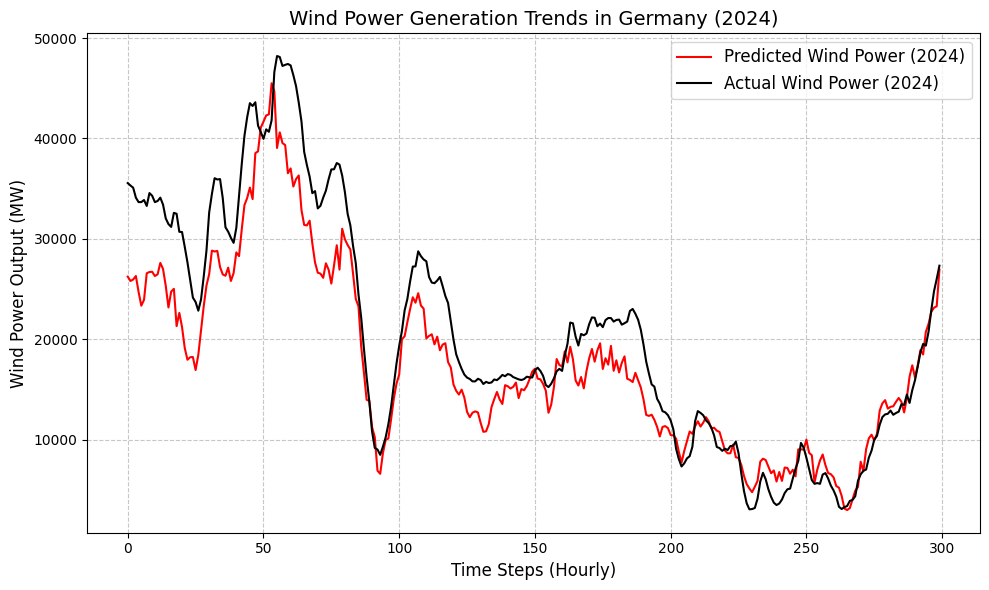

In [26]:
import matplotlib.pyplot as plt
import numpy as np

# Sample data (replace with your actual arrays)
prediction = Prediction_2024[0:300]
solar_data = np.array(wind_power_gen_data['Total_Wind_Power'])[0:300]

# Plot the line graph
plt.figure(figsize=(10, 6))  # Set the figure size

# Plot both data sets
plt.plot(prediction, label='Predicted Wind Power (2024)', color='red')
plt.plot(solar_data, label='Actual Wind Power (2024)', color='black')

# Add title and labels
plt.title('Wind Power Generation Trends in Germany (2024)', fontsize=14)
plt.ylabel('Wind Power Output (MW)', fontsize=12)
plt.xlabel('Time Steps (Hourly)', fontsize=12)

# Add legend
plt.legend(fontsize=12)

# Grid for better readability
plt.grid(True, linestyle='--', alpha=0.7)

# Show the plot
plt.tight_layout()
plt.show()


In [34]:
time_data.shape, Prediction_2024.shape

((7320,), (7320,))

In [37]:
wind_power = pd.DataFrame({
    'MTU':time_data,
    'Wind_Power':Prediction_2024

})

wind_power.sample(10)

,MTU,Wind_Power
7274,2024-10-30 02:00:00,6517.410156
5392,2024-08-12 16:00:00,3675.795410
2895,2024-04-30 15:00:00,7359.173340
3544,2024-05-27 16:00:00,1877.636841
4758,2024-07-17 06:00:00,13647.075195
5532,2024-08-18 12:00:00,2786.764648
6473,2024-09-26 17:00:00,19986.107422
6636,2024-10-03 12:00:00,10575.268555
6151,2024-09-13 07:00:00,8416.605469
3770,2024-06-06 02:00:00,7476.254395
